# **Telco**
Your task is to come up with a plan to take advantage of Telco's
immense amount of data in order to decide who to target with the retention offer. Be as specific as possible about what data would you use, how would you use it, and how would you decide who to target given a limited budget for retention incentives.

Use your best judgment regarding the type of data TelCo could possibly have.

## **0.1. Data Exploration and Preparation**

#### The Telco Case - Prediction on Churn


In [ ]:
# import libraries used for data management
import numpy as np
import pandas as pd

# Import useful library
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import cross_val_score

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score, f1_score, roc_curve, auc

import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

In [ ]:
# Load Datasets
# Manual File input
data = pd.read_csv('data/churn.csv')


In [ ]:
# Load Datasets
# from google.colab import drive
# drive.mount('/content/drive/')

# Load the churn data
# data = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/ISOM3360/Assignment_1/churn.csv')

In [ ]:
# # Make the index from 1
data.index = data.index + 1

# Display the first few rows
display(data.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn
1,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,No
2,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,No
3,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,Yes
4,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,No
5,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,Yes


In [ ]:
# Get Data Frame Information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 1 to 7032
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 


In [ ]:
# Check if there any NA data
print(data.isnull().any())

gender              False
SeniorCitizen       False
Partner             False
Dependents          False
tenure              False
PhoneService        False
MultipleLines       False
InternetService     False
OnlineSecurity      False
OnlineBackup        False
DeviceProtection    False
TechSupport         False
StreamingTV         False
StreamingMovies     False
Contract            False
PaperlessBilling    False
PaymentMethod       False
MonthlyCharges      False
Churn               False
dtype: bool


## **0.2. Preprocessing Data**

In [ ]:
# Tranform binary choices column into numerical
data = pd.get_dummies(data, columns=['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling','PaymentMethod'], drop_first=True)
data=data.replace({True:1, False:0})
data=data.replace({'Yes':1, 'No':0})
display(data.head())

/tmp/ipython-input-1361464670.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data=data.replace({True:1, False:0})
/tmp/ipython-input-1361464670.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data=data.replace({'Yes':1, 'No':0})


,SeniorCitizen,tenure,MonthlyCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1,0,1,29.85,0,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
2,0,34,56.95,0,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0,2,53.85,1,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
4,0,45,42.30,0,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
5,0,2,70.70,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [ ]:
# Define attributes and target variable
features = data.columns.drop('Churn').tolist()
target = ['Churn']

# Specifying Attributes and Target Variable into Dataframe
x = data[features]
y = data[target]

In [ ]:
# Split data into: Training Size 70%, Testing Size 30%
# We use random_state = 23 for alignment with lab
  x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state=23)

In [ ]:
# Normalize for X_train
from sklearn import preprocessing
zscore_scaler = preprocessing.StandardScaler().fit(x_train)

# Transform X_train
x_train_scaled = pd.DataFrame(zscore_scaler.transform(x_train), columns = x_train.columns)

# Use the scale of X_train to transform X_test
x_test_scaled = pd.DataFrame(zscore_scaler.transform(x_test), columns = x_test.columns)

In [ ]:
# Display the scaled training and testing data
print("x_train_scaled:")
display(x_train_scaled.head())
print("\nx_test_scaled")
display(x_test_scaled.head())

x_train_scaled:


,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-0.441203,-0.415501,-1.330409,0.981879,-0.966038,-0.654464,0.320696,-0.320696,1.168908,-0.889450,...,1.899635,-0.786139,1.899635,-0.795982,-0.514753,-0.557795,0.850523,1.926148,-0.717260,-0.541185
1,-0.441203,-0.293275,1.006962,-1.018456,1.035156,-0.654464,0.320696,-0.320696,-0.855499,1.124291,...,-0.526417,1.272040,-0.526417,1.256309,-0.514753,-0.557795,0.850523,-0.519171,1.394195,-0.541185
2,2.266530,-1.026635,-0.022079,0.981879,1.035156,-0.654464,0.320696,-0.320696,1.168908,-0.889450,...,-0.526417,-0.786139,-0.526417,-0.795982,-0.514753,-0.557795,-1.175747,-0.519171,1.394195,-0.541185
3,-0.441203,0.114148,0.825758,0.981879,1.035156,1.527969,0.320696,-0.320696,-0.855499,1.124291,...,-0.526417,1.272040,-0.526417,-0.795982,1.942680,-0.557795,0.850523,-0.519171,1.394195,-0.541185
4,-0.441203,-1.026635,0.676140,0.981879,-0.966038,-0.654464,0.320696,-0.320696,1.168908,1.124291,...,-0.526417,-0.786139,-0.526417,1.256309,-0.514753,-0.557795,0.850523,-0.519171,-0.717260,1.847796



x_test_scaled


,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-0.441203,-0.822924,0.656190,-1.018456,-0.966038,-0.654464,0.320696,-0.320696,-0.855499,1.124291,...,-0.526417,-0.786139,-0.526417,1.256309,-0.514753,-0.557795,0.850523,-0.519171,1.394195,-0.541185
1,-0.441203,-0.822924,0.488285,-1.018456,-0.966038,-0.654464,0.320696,-0.320696,1.168908,1.124291,...,-0.526417,-0.786139,-0.526417,-0.795982,-0.514753,-0.557795,0.850523,1.926148,-0.717260,-0.541185
2,-0.441203,0.888250,1.169880,-1.018456,-0.966038,-0.654464,0.320696,-0.320696,-0.855499,1.124291,...,-0.526417,1.272040,-0.526417,1.256309,1.942680,-0.557795,0.850523,1.926148,-0.717260,-0.541185
3,-0.441203,1.417899,0.940465,0.981879,1.035156,-0.654464,0.320696,-0.320696,1.168908,1.124291,...,-0.526417,-0.786139,-0.526417,1.256309,-0.514753,1.792775,0.850523,-0.519171,1.394195,-0.541185
4,-0.441203,-0.211790,-1.480027,0.981879,-0.966038,-0.654464,0.320696,-0.320696,-0.855499,-0.889450,...,1.899635,-0.786139,1.899635,-0.795982,-0.514753,1.792775,-1.175747,1.926148,-0.717260,-0.541185



# **Task 1: Compare the predictive performance of the two machine learning methods**

---


**Question 1: What is the performance of the logistic regression?**

a. Please first build a Logistic regression model with no regularization, report the Accuracy, Precision, Recall and AUC.

b. Next, use Lasso regularization. Try to systematically experiment with different levels of regularization, adjust the strength parameter from Weak to Strong. Report the best model performance, what is the value of strength parameter (alpha), what are the variables being kept.

c. Based on your findings in part b, please characterize the high- and low-probability churning customers with the logistic regression results. Is the output of data-driven analysis same or different from your intuitions?

## **1.1. Logistic Regression**

### 1.1.1. Logistic Regression (Raw)

In [ ]:
# Define a logistic regression model
logistic_model = LogisticRegression(random_state=23)

# Fit the model
logistic_model_fit = logistic_model.fit(x_train_scaled, y_train.values.ravel())
logistic_model_fit

LogisticRegression(random_state=23)

In [ ]:
# Logistic Regression for testing data
logistic_pred = logistic_model.predict(x_test_scaled)

# Evaluating model based on testing data
logistic_acc = accuracy_score (y_test, logistic_pred)

# Print accuracy result
print(f"Accuracy: {logistic_acc}")

Accuracy: 0.8052132701421801


In [ ]:
# Confusion Matrix with Threshold
print(f'Confusion Matrix:','\n', confusion_matrix(y_test, logistic_pred))

tn, fp, fn, tp = confusion_matrix(y_test, logistic_pred).ravel()
Accuracy =((tp+tn)/(tp+fn+fp+tn))
Precision = (tp/(tp+fp))
Recall = (tp/(tp+fn))


print(f'\nTrue Negative = {tn}')
print(f'False Positive = {fp}')
print(f'False Negative = {fn}')
print(f'True Positive = {tp}')
print(f'\nAccuracy = {Accuracy}')
print(f'Precision = {Precision}')
print(f'Recall = {Recall}')


Confusion Matrix: 
 [[1386  137]
 [ 274  313]]

True Negative = 1386
False Positive = 137
False Negative = 274
True Positive = 313

Accuracy = 0.8052132701421801
Precision = 0.6955555555555556
Recall = 0.5332197614991482


### 1.1.2. Training Dataset

####  Cross Validation

In [ ]:
k_folds = 10

# Cross-Validation
logistic_score = cross_val_score(logistic_model, x_train_scaled, y_train.values.ravel(), cv = k_folds)

# Result for cross-validation model in each iteration
for i in range(k_folds):
    print(f"Iteration #{i + 1} = {logistic_score[i]}")

print(f"\nAverage Model Result = {logistic_score.mean()}")

Iteration #1 = 0.8194726166328601
Iteration #2 = 0.8154158215010142
Iteration #3 = 0.7865853658536586
Iteration #4 = 0.7764227642276422
Iteration #5 = 0.7947154471544715
Iteration #6 = 0.7947154471544715
Iteration #7 = 0.8109756097560976
Iteration #8 = 0.8008130081300813
Iteration #9 = 0.8211382113821138
Iteration #10 = 0.823170731707317

Average Model Result = 0.8043425023499727


In [ ]:
# Cross-validation prediction with predict_proba
logistic_preds_proba_train = cross_val_predict(logistic_model, x_train_scaled, y_train.values.ravel(),cv=k_folds, method='predict_proba')

# Prediction from cross-validation on train set
logistic_preds_cv_train = cross_val_predict(logistic_model, x_train_scaled, y_train.values.ravel(), cv= k_folds)


#  Shows the probability of the result whether 0 or 1
display(pd.DataFrame(logistic_preds_proba_train, columns=['No (0)', 'Yes (1)']).head())

,No (0),Yes (1)
0,0.850433,0.149567
1,0.432299,0.567701
2,0.746042,0.253958
3,0.778475,0.221525
4,0.303554,0.696446


In [ ]:
# Confusion Matrix with Default Threshold (0.5)
print('Confusion Matrix with default threshold of 0.5:','\n', confusion_matrix(y_train, logistic_preds_cv_train))

tn, fp, fn, tp = confusion_matrix(y_train, logistic_preds_cv_train).ravel()
Accuracy =((tp+tn)/(tp+fn+fp+tn))
Precision = (tp/(tp+fp))
Recall = (tp/(tp+fn))

print(f'\nTrue Negative = {tn}')
print(f'False Positive = {fp}')
print(f'False Negative = {fn}')
print(f'True Positive = {tp}')
print(f'\nAccuracy = {Accuracy}')
print(f'Precision = {Precision}')
print(f'Recall = {Recall}')

Confusion Matrix with default threshold of 0.5: 
 [[3281  359]
 [ 604  678]]

True Negative = 3281
False Positive = 359
False Negative = 604
True Positive = 678

Accuracy = 0.8043478260869565
Precision = 0.6538090646094503
Recall = 0.5288611544461779


####ROC Visualization

In [ ]:
logistic_preds_proba_train = logistic_model_fit.predict_proba(x_train_scaled)
logistic_fpr, logistic_tpr, logistic_thresholds = roc_curve(y_train, logistic_preds_proba_train[:, 1])

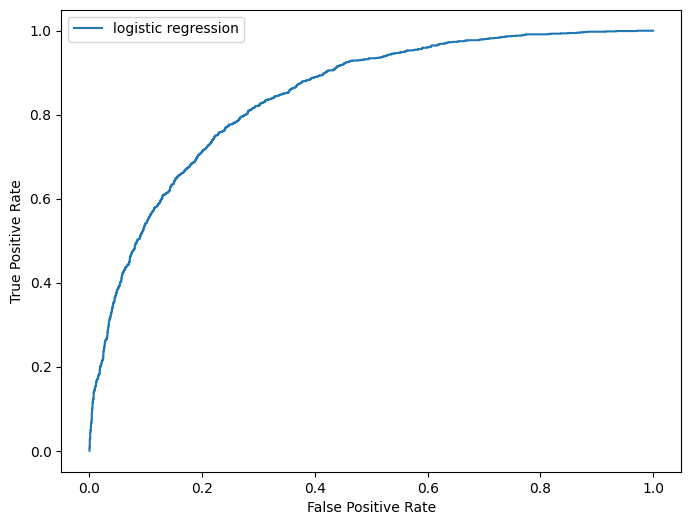

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(logistic_fpr, logistic_tpr, label="logistic regression")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
# Get AUC
logistic_auc = auc(logistic_fpr, logistic_tpr)
print(logistic_auc)

0.842981433543056


### 1.1.3. L1 and L2 Regularization

In [ ]:
logistic_model = LogisticRegression(random_state=23)
logistic_model_l1 = LogisticRegression(penalty='l1',max_iter=1000, solver = 'liblinear')
logistic_model_l2 = LogisticRegression(penalty='l2',max_iter=1000)

In [ ]:
# Search for best complexity when optimizing for AUC for logistic regression
grid_list = [10**i for i in np.arange(-1, 0, 0.1)]
l1_grid = {"C": grid_list}
l1_searcher = GridSearchCV(logistic_model_l1, l1_grid, cv=10)
l1_searcher.fit(x_train_scaled, y_train.values.ravel())

# Best Result
print(f"Best C for logistic regression L1: {l1_searcher.best_params_}")
print(f"Best AUC: {l1_searcher.best_score_}")

Best C for logistic regression L1: {'C': np.float64(0.1)}
Best AUC: 0.8049514338956778


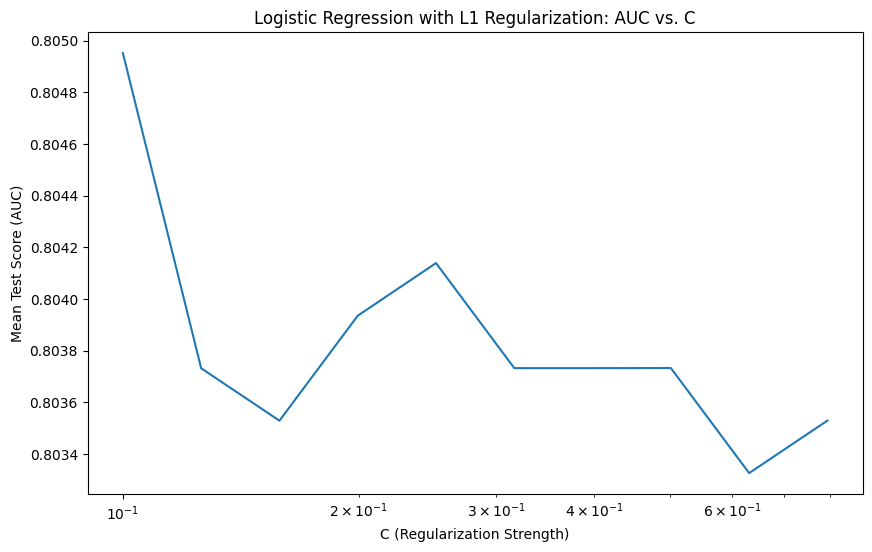

In [ ]:
mean_test_scores = l1_searcher.cv_results_['mean_test_score']
c_values = grid_list

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(c_values, mean_test_scores)
plt.xscale('log')
plt.xlabel('C (Regularization Strength)')
plt.ylabel('Mean Test Score (AUC)')
plt.title('Logistic Regression with L1 Regularization: AUC vs. C')
plt.show()

In [ ]:
# Search for best complexity when optimizing for AUC for logistic regression
grid_list = [10**i for i in np.arange(-1, 0, 0.1)]
l2_grid = {"C": grid_list}
l2_searcher = GridSearchCV(logistic_model_l2, l2_grid, cv=10)
l2_searcher.fit(x_train_scaled, y_train.values.ravel())

# Plot result
print(f"Best C for logistic regression L2: {l2_searcher.best_params_}")
print(f"Best AUC: {l2_searcher.best_score_}")

Best C for logistic regression L2: {'C': np.float64(0.7943282347242812)}
Best AUC: 0.8043425023499727


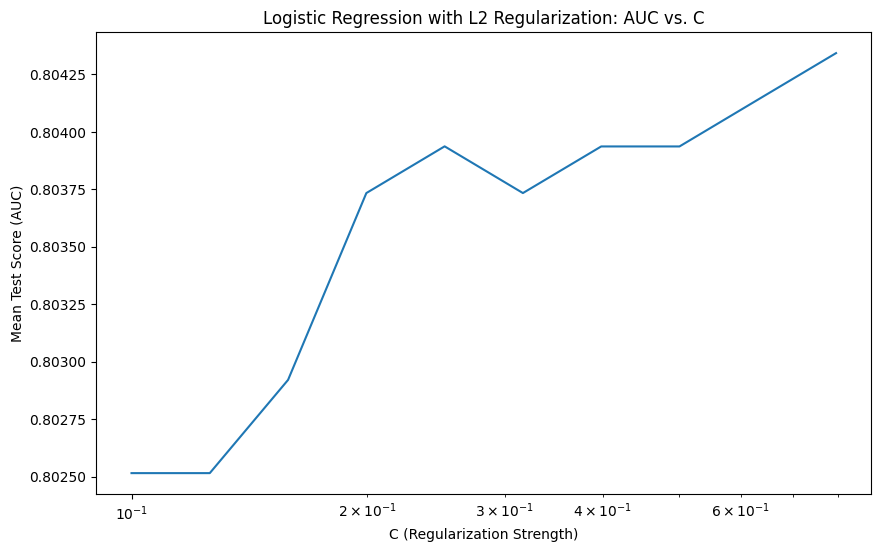

In [ ]:
mean_test_scores = l2_searcher.cv_results_['mean_test_score']
c_values = grid_list

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(c_values, mean_test_scores)
plt.xscale('log')
plt.xlabel('C (Regularization Strength)')
plt.ylabel('Mean Test Score (AUC)')
plt.title('Logistic Regression with L2 Regularization: AUC vs. C')
plt.show()

In [ ]:
# Logistic regression  L1 and L2 with best value of C
logistic_l1 = LogisticRegression(penalty='l1', solver = 'liblinear', C = 0.1, random_state=23)
logistic_l2 = LogisticRegression(penalty='l2', C = l2_searcher.best_params_['C'], random_state=23)

In [ ]:
# fit training data
logistic_l1_fit = logistic_l1.fit(x_train_scaled, y_train.values.ravel())
logistic_l2_fit = logistic_l2.fit(x_train_scaled, y_train.values.ravel())

In [ ]:
logistic_regression_l1 = accuracy_score(y_test, logistic_l1_fit.predict(x_test_scaled), normalize=True, sample_weight=None)
print(logistic_regression_l1)

logistic_regression_l2 = accuracy_score(y_test, logistic_l2_fit.predict(x_test_scaled), normalize=True, sample_weight=None)
print(logistic_regression_l2)

0.8037914691943128
0.8052132701421801


In [ ]:
# L2 Regularization Confusion Matrix
print(f'Confusion Matrix:','\n', confusion_matrix(y_test, logistic_pred))

tn, fp, fn, tp = confusion_matrix(y_test, logistic_l2_fit.predict(x_test_scaled)).ravel()
Accuracy =((tp+tn)/(tp+fn+fp+tn))
Precision = (tp/(tp+fp))
Recall = (tp/(tp+fn))


print(f'\nTrue Negative = {tn}')
print(f'False Positive = {fp}')
print(f'False Negative = {fn}')
print(f'True Positive = {tp}')
print(f'\nAccuracy = {Accuracy}')
print(f'Precision = {Precision}')
print(f'Recall = {Recall}')

Confusion Matrix: 
 [[1386  137]
 [ 274  313]]

True Negative = 1386
False Positive = 137
False Negative = 274
True Positive = 313

Accuracy = 0.8052132701421801
Precision = 0.6955555555555556
Recall = 0.5332197614991482


In [ ]:
coeff_df = pd.DataFrame(list(zip(logistic_model_fit.coef_.flatten(), logistic_l1_fit.coef_.flatten(), logistic_l2_fit.coef_.flatten())),
                        columns=['Logistic','L1', 'L2'], index=features)
display(coeff_df)

,Logistic,L1,L2
SeniorCitizen,0.054115,0.049107,0.054052
tenure,-0.853843,-0.840549,-0.852990
MonthlyCharges,-0.239945,0.000000,-0.182288
gender_Male,-0.037217,-0.020365,-0.037245
Partner_Yes,-0.007106,0.000000,-0.007118
Dependents_Yes,-0.057440,-0.051299,-0.057536
PhoneService_Yes,-0.049359,-0.017895,-0.054816
MultipleLines_No phone service,0.049359,0.103567,0.054816
MultipleLines_Yes,0.180808,0.136603,0.175792
InternetService_Fiber optic,0.552559,0.441397,0.528389


## **1.2. Decision Tree**

**Question 2: What is the most effective decision tree you can build?**



### **1.2.1. Purity Measure**

#### 1.2.1.1. Purity Measure: Entropy

In [ ]:
# define our model decision tree model
dt_model = DecisionTreeClassifier(criterion='entropy', random_state = 23)

# Build the decision tree model using the same split as logistic regression
dt_model.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=23)

In [ ]:
# test evaluation result for 70% train data
y_pred_train = dt_model.predict(x_train)

# print evaluation result for 70% train data
print("Accuracy from 70% train data:",accuracy_score(y_train, y_pred_train, normalize=True, sample_weight=None))

Accuracy from 70% train data: 0.997765136123527


In [ ]:
# test model base on 30% hold out data
y_pred_test = dt_model.predict(x_test)

# print evaluation result for 30% test data
print("Accuracy from 30% test data:",accuracy_score(y_test, y_pred_test, normalize=True, sample_weight=None))

Accuracy from 30% test data: 0.7241706161137441


#### 1.2.1.2. Purity Measure: Gini

In [ ]:
# define our model decision tree model
dt_model_gini = DecisionTreeClassifier(criterion='gini',random_state = 23)

# Build the decision tree model using the same split as logistic regression
dt_model_gini.fit(x_train, y_train)

DecisionTreeClassifier(random_state=23)

In [ ]:
# test evaluation result for 70% train data
y_pred_train = dt_model_gini.predict(x_train)

# print evaluation result for 70% train data
print("Accuracy from 70% train data:",accuracy_score(y_train, y_pred_train, normalize=True, sample_weight=None))

Accuracy from 70% train data: 0.997765136123527


In [ ]:
# test model base on 30% hold out data
y_pred_test = dt_model_gini.predict(x_test)

# print evaluation result for 30% test data
print("Accuracy from 30% test data:",accuracy_score(y_test, y_pred_test, normalize=True, sample_weight=None))

Accuracy from 30% test data: 0.7151658767772512


#### 1.2.1.3. Purity Measure: Log_loss

In [ ]:
# define our model decision tree model
dt_model_log = DecisionTreeClassifier(criterion='log_loss',random_state = 23)

# Build the decision tree model using the same split as logistic regression
dt_model_log.fit(x_train, y_train)

DecisionTreeClassifier(criterion='log_loss', random_state=23)

In [ ]:
# test evaluation result for 70% train data
y_pred_train = dt_model_log.predict(x_train)

# print evaluation result for 70% train data
print("Accuracy from 70% train data:",accuracy_score(y_train, y_pred_train, normalize=True, sample_weight=None))

Accuracy from 70% train data: 0.997765136123527


In [ ]:
# test model base on 30% hold out data
y_pred_test = dt_model_gini.predict(x_test)

# print evaluation result for 30% test data
print("Accuracy from 30% test data:",accuracy_score(y_test, y_pred_test, normalize=True, sample_weight=None))

Accuracy from 30% test data: 0.7151658767772512


### **1.2.2. Hyperparameter**

#### 1.2.2.1. max_depth

In [ ]:
from matplotlib import pyplot as plt
# Evaluate the decision tree at different depths
depths = range(1, 21)
accuracy_scores_test = []
accuracy_scores_train = []

for depth in depths:
    dt_model = DecisionTreeClassifier(max_depth=depth, criterion='entropy')
    dt_model.fit(x_train, y_train)
    y_pred_train =dt_model.predict(x_train)
    y_pred_test = dt_model.predict(x_test)
    accuracy_scores_train.append(accuracy_score(y_train, y_pred_train))
    accuracy_scores_test.append(accuracy_score(y_test, y_pred_test))

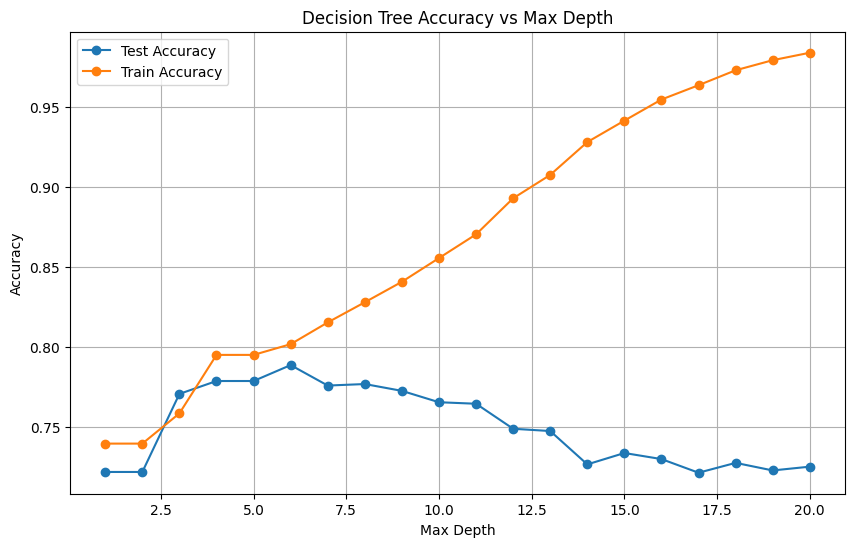

In [ ]:
# Plot the accuracy vs depth
plt.figure(figsize=(10, 6))
plt.plot(depths, accuracy_scores_test, marker='o', label='Test Accuracy')
plt.plot(depths, accuracy_scores_train, marker='o', label='Train Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs Max Depth')
plt.legend()
plt.grid(True)
plt.show()

#### 1.2.2.3. min_samples_leaf

In [ ]:
# Evaluate the decision tree at different min_samples_leaf
min_samples_leaf_values = range(1, 21)
accuracy_scores_test_leaf = []
accuracy_scores_train_leaf = []

for min_samples in min_samples_leaf_values:
    dt_model = DecisionTreeClassifier(min_samples_leaf=min_samples, criterion='entropy')
    dt_model.fit(x_train, y_train)
    y_pred_train = dt_model.predict(x_train)
    y_pred_test = dt_model.predict(x_test)
    accuracy_scores_train_leaf.append(accuracy_score(y_train, y_pred_train))
    accuracy_scores_test_leaf.append(accuracy_score(y_test, y_pred_test))

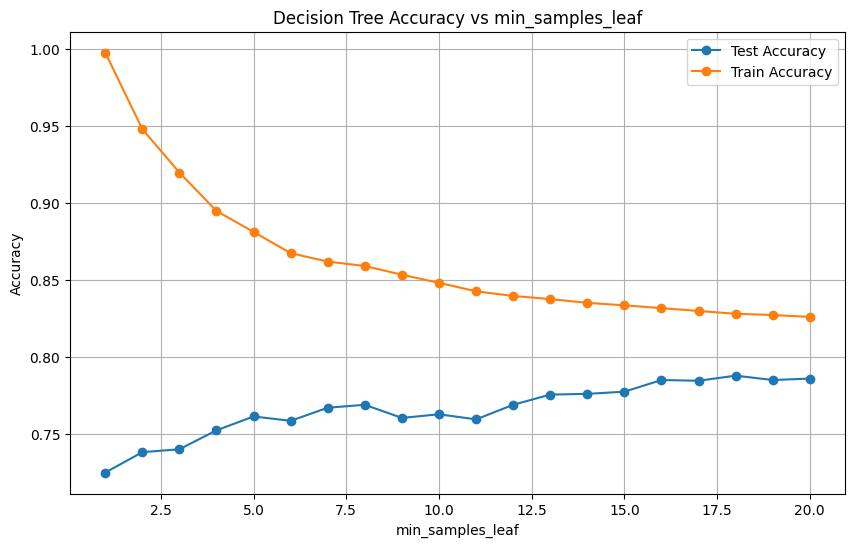

In [ ]:
# Plot the accuracy vs min_samples_leaf
plt.figure(figsize=(10, 6))
plt.plot(min_samples_leaf_values, accuracy_scores_test_leaf, marker='o', label='Test Accuracy')
plt.plot(min_samples_leaf_values, accuracy_scores_train_leaf, marker='o', label='Train Accuracy')
plt.xlabel('min_samples_leaf')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs min_samples_leaf')
plt.legend()
plt.grid(True)
plt.show()

#### 1.2.2.3. max_leaf_nodes

In [ ]:
# Evaluate the decision tree at different max_leaf_nodes
max_leaf_nodes_values = range(2, 101, 2)
accuracy_scores_test_leaf_nodes = []
accuracy_scores_train_leaf_nodes = []

for max_leaf in max_leaf_nodes_values:
    dt_model = DecisionTreeClassifier(max_leaf_nodes=max_leaf, criterion='entropy')
    dt_model.fit(x_train, y_train)
    y_pred_train = dt_model.predict(x_train)
    y_pred_test = dt_model.predict(x_test)
    accuracy_scores_train_leaf_nodes.append(accuracy_score(y_train, y_pred_train))
    accuracy_scores_test_leaf_nodes.append(accuracy_score(y_test, y_pred_test))

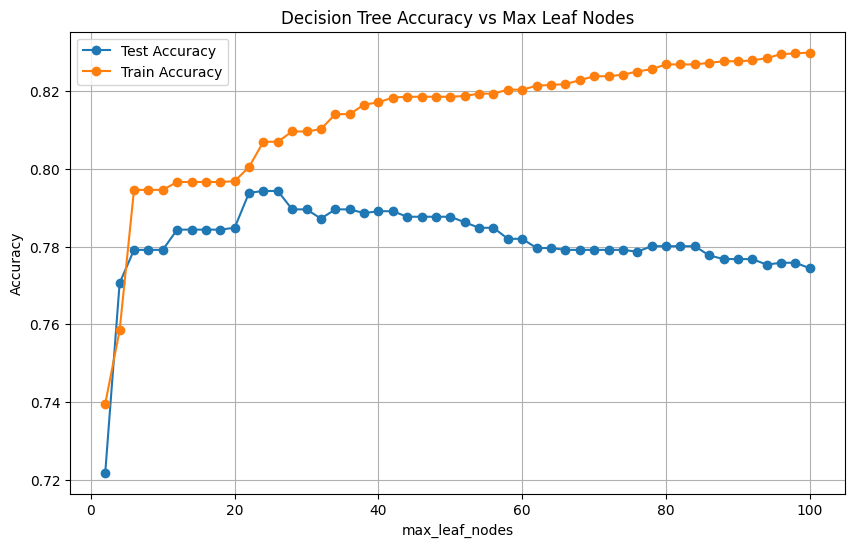

In [ ]:
# Plot the accuracy vs min_samples_leaf
plt.figure(figsize=(10, 6))
plt.plot(max_leaf_nodes_values, accuracy_scores_test_leaf_nodes, marker='o', label='Test Accuracy')
plt.plot(max_leaf_nodes_values, accuracy_scores_train_leaf_nodes, marker='o', label='Train Accuracy')
plt.xlabel('max_leaf_nodes')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs Max Leaf Nodes')
plt.legend()
plt.grid(True)
plt.show()

#### 1.2.2.4. min_impurity_decrease

In [ ]:
# Evaluate the decision tree at different min_impurity_decrease
min_impurity_decrease_values = [
    0, 1e-6, 1e-5, 1e-4, 0.0005, 0.001, 0.002, 0.003,
    0.005, 0.007, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05,
    0.07, 0.1
]


accuracy_scores_test_impurity = []
accuracy_scores_train_impurity = []

for min_impurity in min_impurity_decrease_values:
    dt_model = DecisionTreeClassifier(min_impurity_decrease=min_impurity, criterion='entropy')
    dt_model.fit(x_train, y_train)
    y_pred_train = dt_model.predict(x_train)
    y_pred_test = dt_model.predict(x_test)
    accuracy_scores_train_impurity.append(accuracy_score(y_train, y_pred_train))
    accuracy_scores_test_impurity.append(accuracy_score(y_test, y_pred_test))

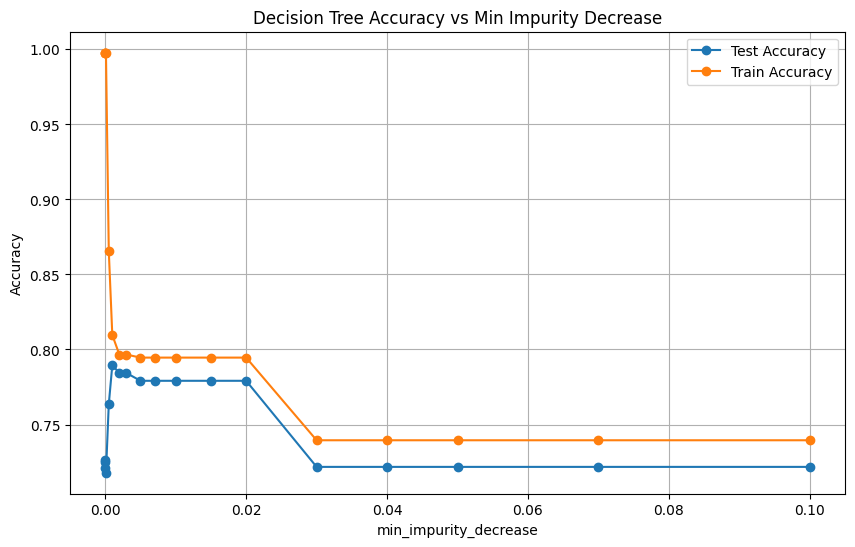

In [ ]:
# Plot the accuracy vs min_impurity_decrease
plt.figure(figsize=(10, 6))
plt.plot(min_impurity_decrease_values, accuracy_scores_test_impurity, marker='o', label='Test Accuracy')
plt.plot(min_impurity_decrease_values, accuracy_scores_train_impurity, marker='o', label='Train Accuracy')
plt.xlabel('min_impurity_decrease')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs Min Impurity Decrease')
plt.legend()
plt.grid(True)
plt.show()

#### 1.2.2.4. max_feature

In [ ]:
# Evaluate the decision tree at different min_impurity_decrease
max_feature_value = range(1,40,1)


accuracy_scores_test_impurity = []
accuracy_scores_train_impurity = []

for max_feature in max_feature_value:
    dt_model = DecisionTreeClassifier(max_features=max_feature, criterion='entropy', random_state=23)
    dt_model.fit(x_train, y_train)
    y_pred_train = dt_model.predict(x_train)
    y_pred_test = dt_model.predict(x_test)
    accuracy_scores_train_impurity.append(accuracy_score(y_train, y_pred_train))
    accuracy_scores_test_impurity.append(accuracy_score(y_test, y_pred_test))

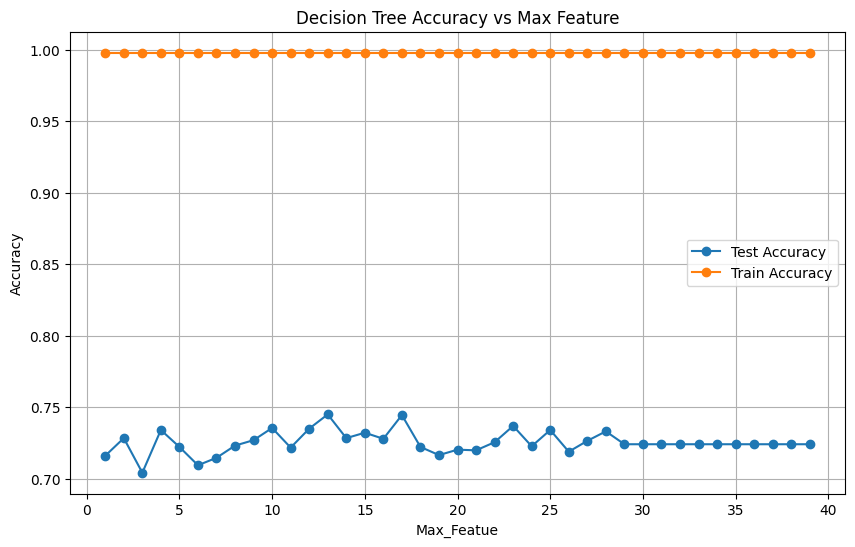

In [ ]:
# Plot the accuracy vs min_impurity_decrease
plt.figure(figsize=(10, 6))
plt.plot(max_feature_value, accuracy_scores_test_impurity, marker='o', label='Test Accuracy')
plt.plot(max_feature_value, accuracy_scores_train_impurity, marker='o', label='Train Accuracy')
plt.xlabel('Max_Featue')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy vs Max Feature')
plt.legend()
plt.grid(True)
plt.show()

### **1.2.3. GridSearchCV (Finding the Best Result)**

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the model
dt_model = DecisionTreeClassifier(criterion = 'entropy', random_state=23)

# Define hyperparameter grid
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'max_leaf_nodes': [5, 10, 20, 50, 100],
    'min_samples_leaf': [1, 2, 4],
}

# Set up grid search
DTM = GridSearchCV(dt_model, param_grid, cv=10)
DTM.fit(x_train, y_train)

print("Best Accuracy:", DTM.best_score_)
print("Best Parameters:", DTM.best_params_)

Best Accuracy: 0.7929649235640429
Best Parameters: {'max_depth': 5, 'max_leaf_nodes': 5, 'min_samples_leaf': 1}


In [ ]:
# Define the number to try out for max leaf nodes
max_depth = np.arange(5,15,1).tolist()
min_samples_leaf = np.arange(1,4,1).tolist()
max_leaf_nodes = [5, 10, 20, 50, 100]

# Define the parameter grid
try_grid = {
    'max_depth': max_depth,
    'min_samples_leaf': min_samples_leaf,
    'max_leaf_nodes': max_leaf_nodes
}


In [ ]:
# Define your Model using GridSearchCV
dt_model = DecisionTreeClassifier(criterion = 'entropy', random_state=23)

GSCV_model = GridSearchCV(dt_model, try_grid)

# Fit the training data
GSCV_model.fit(x_train, y_train)

GridSearchCV(estimator=DecisionTreeClassifier(criterion='entropy',
                                              random_state=23),
             param_grid={'max_depth': [5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
                         'max_leaf_nodes': [5, 10, 20, 50, 100],
                         'min_samples_leaf': [1, 2, 3]})

In [ ]:
best_max_depth = (GSCV_model.best_params_['max_depth'])
best_max_node_leaf = (GSCV_model.best_params_['max_leaf_nodes'])
best_min_samples_leaf = (GSCV_model.best_params_['min_samples_leaf'])
print(best_max_depth)
print(best_max_node_leaf)
print(best_min_samples_leaf)


5
5
1


In [ ]:
#  fit a new model with training dataset, setting the best parameter values
Best_DT_model = DecisionTreeClassifier(criterion = 'entropy', max_leaf_nodes = best_max_node_leaf, max_depth = best_max_depth, min_samples_leaf = best_min_samples_leaf, random_state =23)
Best_DT_model_fit = Best_DT_model.fit(x_train, y_train)
Best_DT_model_fit

DecisionTreeClassifier(criterion='entropy', max_depth=5, max_leaf_nodes=5,
                       random_state=23)

In [ ]:
Best_DT_pred = Best_DT_model_fit.predict(x_test)
Best_DT_Acc = accuracy_score(y_test, Best_DT_pred)
Best_DT_Acc

0.7791469194312797

In [ ]:
Best_DT_model = GSCV_model.best_estimator_
DT_feature = x_train.columns[Best_DT_model.feature_importances_ > 0].tolist()
print(f"Features used in the tree: {DT_feature}")

Features used in the tree: ['tenure', 'InternetService_Fiber optic', 'Contract_One year', 'Contract_Two year']


In [ ]:
important = pd.Series(Best_DT_model.feature_importances_, index=x_train.columns)
important_features = important[important > 0].sort_values(ascending=0)

# Display the important features
print("\nImportant Features in Best Decision Tree Model:")
print(important_features)



Important Features in Best Decision Tree Model:
Contract_Two year              0.437313
Contract_One year              0.301423
InternetService_Fiber optic    0.146099
tenure                         0.115165
dtype: float64


In [ ]:
tree_ = Best_DT_model.predict_proba(x_test)[:, 1]
Best_DT_model_predict = Best_DT_model.predict(x_test)
tree_auc = roc_auc_score(y_test, tree_)


print("Confusion matrix: \n",  confusion_matrix(y_test, Best_DT_model_predict))
print(f"Accuracy= {accuracy_score(y_test, Best_DT_model_predict)}")
print(f"Precision= {precision_score(y_test, Best_DT_model_predict)}")
print(f"Recall= {recall_score(y_test, Best_DT_model_predict)}")
print(f"AUC= {tree_auc}")
print(f"F1 Score= {f1_score(y_test, Best_DT_model_predict)}")

Confusion matrix: 
 [[1435   88]
 [ 378  209]]
Accuracy= 0.7791469194312797
Precision= 0.7037037037037037
Recall= 0.35604770017035775
AUC= 0.8154610565312568
F1 Score= 0.47285067873303166


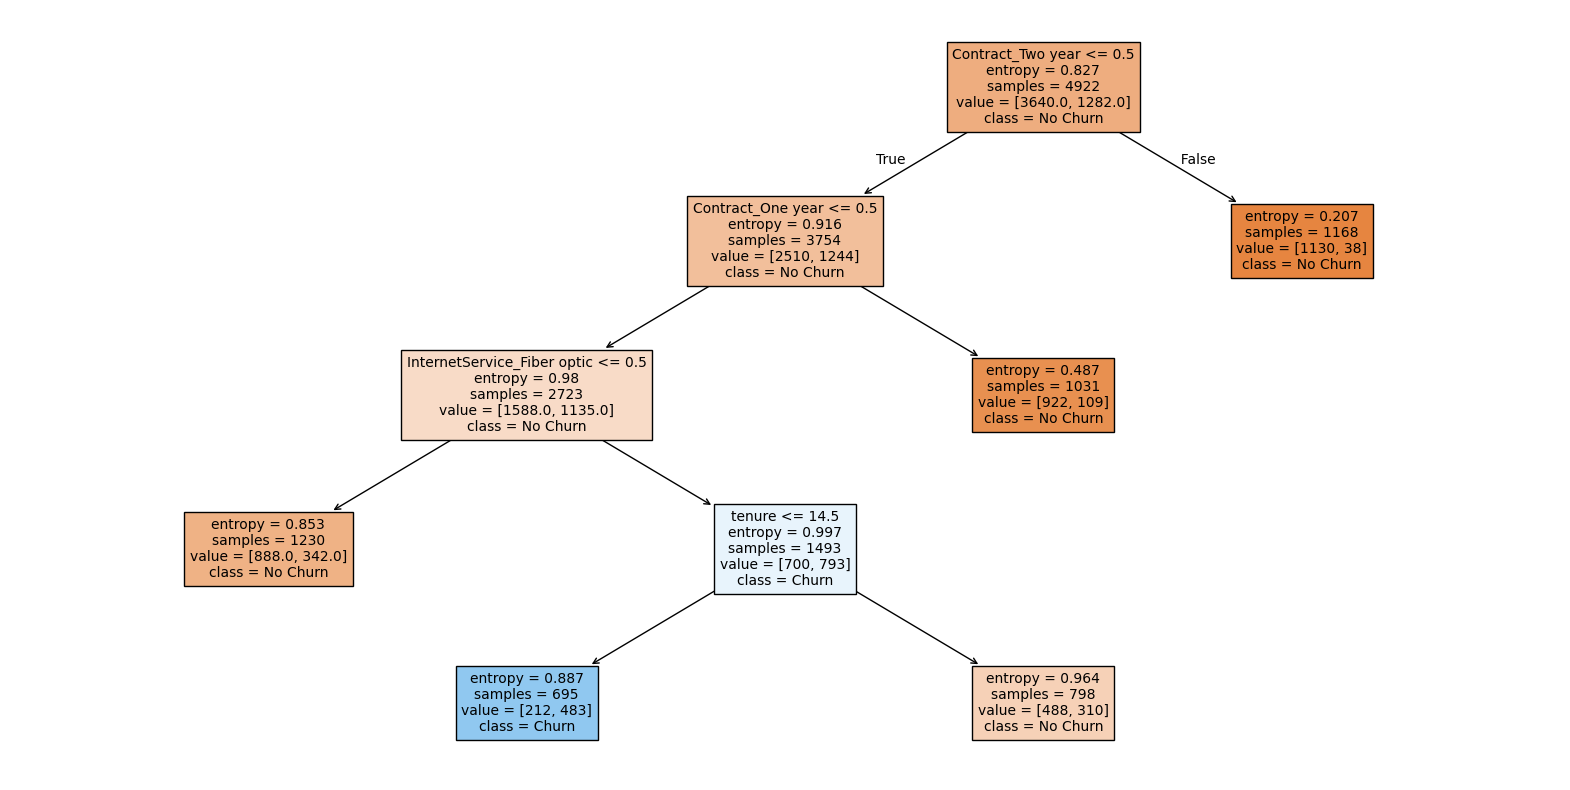

In [ ]:
fig = plt.figure(figsize=(20,10))
_ = tree.plot_tree(Best_DT_model,
                   feature_names = features,
                   class_names = ['No Churn','Churn'],
                   filled=True,
                   fontsize=10)

# **Task 2: Optimize business returns by employing data-driven decision makings solutions.**

---

#### Reevaluate different models with the cost information and customer's contract value

##Data Preparation

In [ ]:
DT_result_df = pd.DataFrame({
    'actual': y_test['Churn'],
    'predicted': Best_DT_pred
}, index = y_test.index)

DT_combined_df = DT_result_df.join(data['MonthlyCharges'])

DT_combined_df.sort_index()

,actual,predicted,MonthlyCharges
3,1,0,53.85
12,0,0,18.95
16,0,0,113.25
19,1,0,55.20
20,0,0,90.05
...,...,...,...
7008,1,1,70.65
7010,0,0,19.20
7011,1,0,59.80
7026,0,0,60.65


In [ ]:
logistic_pred = logistic_l2_fit.predict(x_test_scaled)

log_result_df = pd.DataFrame({
    "actual": y_test['Churn'],
    'predicted':logistic_pred
}, index = y_test.index)

log_combined_df = log_result_df.join(data['MonthlyCharges'], how='left')
log_combined_df.sort_index()

,actual,predicted,MonthlyCharges
3,1,0,53.85
12,0,0,18.95
16,0,0,113.25
19,1,0,55.20
20,0,1,90.05
...,...,...,...
7008,1,1,70.65
7010,0,0,19.20
7011,1,0,59.80
7026,0,0,60.65


## **2.1. Default Decision Threshold = 0.5**
Please use the prediction output from the best logistic regression and decision tree model you built from Task 1 (with the default decision threshold of 0.5) and compare which model gives you better overall performance with the cost information.

Logistic Regression Performance

In [ ]:
FN_log_cost = 0
FP_log_cost = 0

for i in range(len(log_combined_df)):
  if log_combined_df['actual'].iloc[i]==1 and log_combined_df['predicted'].iloc[i]==0:
    FN_log_cost += 205
  if log_combined_df['actual'].iloc[i]==0 and log_combined_df['predicted'].iloc[i]==1:
    FP_log_cost += int((log_combined_df['MonthlyCharges'].iloc[i]*12)-205)

print(f"False Negative cost: {FN_log_cost}")
print(f"False Positive cost: {FP_log_cost}")

Total_cost = FN_log_cost + FP_log_cost
print(f"Logistic Regression Total cost: {Total_cost}")

False Negative cost: 56170
False Positive cost: 107078
Logistic Regression Total cost: 163248


Decision Tree Performance

In [ ]:
DT_FN_cost = 0
DT_FP_cost = 0

for i in range(len(DT_combined_df)):
  if DT_combined_df['actual'].iloc[i]==1 and DT_combined_df['predicted'].iloc[i]==0:
    DT_FN_cost += 205
  if DT_combined_df['actual'].iloc[i]==0 and DT_combined_df['predicted'].iloc[i]==1:
    DT_FP_cost += int((DT_combined_df['MonthlyCharges'].iloc[i]*12)-205)

print(f"False Negative cost: {DT_FN_cost}")
print(f"False Positive cost: {DT_FP_cost}")

Total_cost = DT_FN_cost + DT_FP_cost
print(f"Decision Tree Total cost: {Total_cost}")

False Negative cost: 77490
False Positive cost: 66799
Decision Tree Total cost: 144289


## **2.2. Best Decision Threshold and Minimized Cost**

Logistic Regression

In [ ]:
logistic_thresholds

array([       inf, 0.856763  , 0.84454818, ..., 0.00775871, 0.00774117,
       0.00438943])

In [ ]:
logistic_fpr, logistic_tpr, logistic_thresholds = roc_curve(y_train, logistic_preds_proba_train[:,1])

In [ ]:
logistic_thresholds = np.delete(logistic_thresholds, 0)
cost_list = []

for threshold in logistic_thresholds:
  predicted_labels=np.argmax(logistic_preds_proba_train >= threshold, axis=1)

  #Confusion Matrix
  tn, fp, fn, tp = confusion_matrix(y_train, predicted_labels).ravel() # Use ravel() to flatten the array

  cost = 0

  # Calculate cost for each prediction in the test set
  for i in range(len(y_test)):
    # False Negative: Actual Churn = 1, Predicted Churn = 0
    if y_test['Churn'].iloc[i] == 1 and predicted_labels[i] == 0:
      cost += 205
    # False Positive: Actual Churn = 0, Predicted Churn = 1
    elif y_test['Churn'].iloc[i] == 0 and predicted_labels[i] == 1:
      # Get the monthly charge for the corresponding customer in the test set
      monthly_charge = x_test['MonthlyCharges'].iloc[i] # Use x_test for monthly charges in the test set
      cost += int((monthly_charge * 12) - 205)

  cost_list.append((threshold, cost))
  break

cost_list
# Print the costs for each threshold
for threshold, cost in cost_list:
  print(f"Threshold: {threshold:.4f}, Cost: {cost}")

# Find the threshold with the minimum cost
min_cost_threshold, min_cost = min(cost_list, key=lambda item: item[1])
print(f"\nMinimum cost of {min_cost} is achieved at threshold {min_cost_threshold:.4f}")

Threshold: 0.8568, Cost: 120550

Minimum cost of 120550 is achieved at threshold 0.8568


Decision Tree

In [ ]:
Best_DT_pred_proba = Best_DT_model_fit.predict_proba(x_test)
DT_tresholds = Best_DT_pred_proba[:,1]
DT_tresholds

array([0.69496403, 0.69496403, 0.1057226 , ..., 0.27804878, 0.69496403,
       0.27804878])

In [ ]:
cost_list = []
for threshold in DT_tresholds:
  predicted_labels=np.argmax(Best_DT_pred_proba >= threshold, axis=1)

  #Confusion Matrix
  tn, fp, fn, tp = confusion_matrix(y_test, predicted_labels).ravel() # Use ravel() to flatten the array

  cost = 0

  # Calculate cost for each prediction in the test set
  for i in range(len(y_test)):
    # False Negative: Actual Churn = 1, Predicted Churn = 0
    if y_test['Churn'].iloc[i] == 1 and predicted_labels[i] == 0:
      cost += 205
    # False Positive: Actual Churn = 0, Predicted Churn = 1
    elif y_test['Churn'].iloc[i] == 0 and predicted_labels[i] == 1:
      monthly_charge = x_test['MonthlyCharges'].iloc[i]
      cost += int((monthly_charge * 12) - 205)

  cost_list.append((threshold, cost))

# for threshold, cost in cost_list:
#   print(f"Threshold: {threshold:.4f}, Cost: {cost}")

# Find the threshold with the minimum cost
min_cost_threshold, min_cost = min(cost_list, key=lambda item: item[1])
print(f"Minimum cost of {min_cost} is achieved at threshold {min_cost_threshold:.4f}")

Minimum cost of 120335 is achieved at threshold 0.1057


## **2.3. Non Data-driven Solution**


In [ ]:
# doing nothing = predicting everyone as not churning (all 0)
# sending offer to everyone = predicting everyone as churning (all 1)

In [ ]:
y_test.sort_index()

,Churn
3,1
12,0
16,0
19,1
20,0
...,...
7008,1
7010,0
7011,1
7026,0


Doing nothing --> Predicting everyone not churning --> Churn Predicted = No --> Churn Predicted = 0

In [ ]:
cost = 0
FN_count = 0

for i in range(len(y_test)):
  if y_test['Churn'].iloc[i]== 1:
    cost += (data['MonthlyCharges'].iloc[i]*12)-205
    FN_count += 1
  else:
    continue

print(f"False Negative count: {FN_count}")
print(f"Total cost of predicting everyone as not churning: {cost}")

False Negative count: 587
Total cost of predicting everyone as not churning: 346555.00000000006


Sending offer to everyone --> Predicting everyone churning --> Churn Predicted = Yes --> Churn Predicted = 1


In [ ]:
cost = 0
FP_count = 0

for i in range(len(y_test)):
  if y_test['Churn'].iloc[i]== 0:
    cost += 205
    FP_count += 1
  else:
    continue

print(f"False Positive count: {FP_count}")
print(f"Total cost of predicting everyone churning: {cost}")


False Positive count: 1523
Total cost of predicting everyone churning: 312215


In [ ]:
y_test['Churn']

,Churn
2862,0
4979,0
4843,0
5073,0
6663,0
...,...
4754,0
563,0
494,0
3384,0


## **2.5. Retention Offer Decision Based on Expected Return**


In [ ]:
# define function to calculate cost
def total_cost(y_true, y_pred, contract_value):
    sum = 0
    for i in range(len(y_true)):
        actual = y_true[i]
        pred = y_pred[i]
        value = contract_value[i]

        if pred == 1 and actual == 0:  #fp
            sum += (205)
        elif pred == 0 and actual == 1:  #fn
            sum += (value - 205)
    return sum

### Logistic Regression Cost (Expected Value)

In [ ]:
# Know the customer who has positive expected value
logistic_preds_proba = logistic_l2_fit.predict_proba(x_test_scaled)

datatmp = x_test.copy()
datatmp['contract_value'] = datatmp['MonthlyCharges'] * 12
predicted_offer_labels = pd.Series(0, index=y_test.index)
predicted_offer_labels[(logistic_preds_proba[:, 1] * (x_test['MonthlyCharges'] * 12) - 205) > 0] = 1


In [ ]:
# To align the index with actual result and contract value for calculation
y_test_aligned, predicted_offer_labels_aligned,  = y_test.align(predicted_offer_labels, join='inner', axis=0)
contract_value_aligned = datatmp['contract_value'].align(y_test_aligned, join='inner', axis=0)[0]


In [ ]:
# Calculate the total cost
total_offer_cost_logis = total_cost(y_test_aligned['Churn'].values, predicted_offer_labels_aligned.values, contract_value_aligned.values)

print(f"Total cost for logistic ragression with positive expected value: {total_offer_cost_logis}")


Total cost for logistic ragression with positive expected value: 135867.79999999993


### Decision Tree Cost (Expected Value)

In [ ]:
DT_preds_proba = Best_DT_model_fit.predict_proba(x_test)


In [ ]:
datatmp = x_test.copy()
datatmp['contract_value'] = datatmp['MonthlyCharges'] * 12
predicted_offer_labels = pd.Series(0, index=y_test.index)
predicted_offer_labels[(DT_preds_proba[:, 1] * datatmp['contract_value'] - 205) > 0] = 1

In [ ]:
# To align the index with actual result and contract value for calculation
y_test_aligned, predicted_offer_labels_aligned,  = y_test.align(predicted_offer_labels, join='inner', axis=0)
contract_value_aligned = datatmp['contract_value'].align(y_test_aligned, join='inner', axis=0)[0]


In [ ]:
# Calculate the total cost
total_offer_cost_DT = total_cost(y_test_aligned['Churn'].values, predicted_offer_labels_aligned.values, contract_value_aligned.values)

print(f"Total cost for Decision Tree with positive expected value: {total_offer_cost_DT}")


Total cost for Decision Tree with positive expected value: 160319.79999999987
